# 11 — Test your own images
Loads the final localization model (clean-label run) and shows **where** an image looks AI-edited and **what % of the image** that is.

Run cell 1 once, then call `analyze(path)` for as many images as you like (cell 2). Laptop GPU or CPU both work for single images.

In [1]:
import numpy as np, torch, torch.nn.functional as F, matplotlib.pyplot as plt
import segmentation_models_pytorch as smp
from PIL import Image
from pathlib import Path

P = Path(r"C:\AI_Image_Project")
RUN = "Unet_resnet34_crop512_plusbbox_clean"
ck = torch.load(P / "saved_models" / "localization" / f"{RUN}_deploy.pth", map_location="cpu", weights_only=False)
cfg = ck["cfg"]
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = smp.create_model(arch=cfg["ARCH"], encoder_name=cfg["ENCODER"], encoder_weights=None, in_channels=3, classes=1)
model.load_state_dict(ck["model"]); model.to(device).eval()
MEAN = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1) * 255
STD  = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1) * 255
print("Loaded", RUN, "| threshold", ck["threshold"], "| area method:", ck["quant_estimator"])

@torch.no_grad()
def analyze(path, show=True):
    im = Image.open(path).convert("RGB")
    s = min(1.0, cfg["MAX_SIDE"] / max(im.size))
    if s < 1: im = im.resize((round(im.size[0] * s), round(im.size[1] * s)), Image.Resampling.BICUBIC)
    img = np.asarray(im); H, W = img.shape[:2]
    x = (torch.from_numpy(img.copy()).to(device).permute(2, 0, 1)[None].float() - MEAN) / STD
    x = F.pad(x, (0, (-W) % 32, 0, (-H) % 32), mode="reflect")
    with torch.autocast(device.type, dtype=torch.float16, enabled=device.type == "cuda"):
        p = torch.sigmoid(model(x).float())
        p = 0.5 * (p + torch.sigmoid(model(x.flip(-1)).float()).flip(-1))      # flip TTA, as in evaluation
    prob = p[0, 0, :H, :W].float().cpu().numpy()
    mask = prob >= ck["threshold"]
    hard, soft = 100 * mask.mean(), 100 * prob.mean()
    est = ck["quant_estimator"]
    if est.startswith("Hard mask @MAE"):   area = 100 * (prob >= ck["mae_threshold"]).mean()
    elif est.startswith("Hard mask"):      area = hard
    elif est.startswith("Soft + isotonic"): area = float(np.interp(soft, *ck["iso_soft"]))
    elif est.startswith("Hard + isotonic"): area = float(np.interp(hard, *ck["iso_hard"]))
    else:                                   area = soft
    if show:
        ov = img.copy(); ov[mask] = (0.5 * ov[mask] + [127, 0, 0]).astype(np.uint8)
        fig, ax = plt.subplots(1, 3, figsize=(16, 5.5))
        for a, im_, t in zip(ax, [img, prob, ov], ["input", "AI-edit probability", f"predicted AI-edited area = {area:.2f}%"]):
            a.imshow(im_, cmap="jet" if t.startswith("AI-edit") else None, vmin=0, vmax=1 if t.startswith("AI-edit") else None)
            a.set_title(t); a.axis("off")
        plt.suptitle(Path(path).name); plt.tight_layout(); plt.show()
    print(f"{Path(path).name}: predicted AI-edited area = {area:.2f}%  (max pixel probability {prob.max():.2f})")
    return {"area_pct": area, "mask": mask, "prob": prob}

Loaded Unet_resnet34_crop512_plusbbox_clean | threshold 0.25 | area method: Hard mask @MAE-thr 0.70


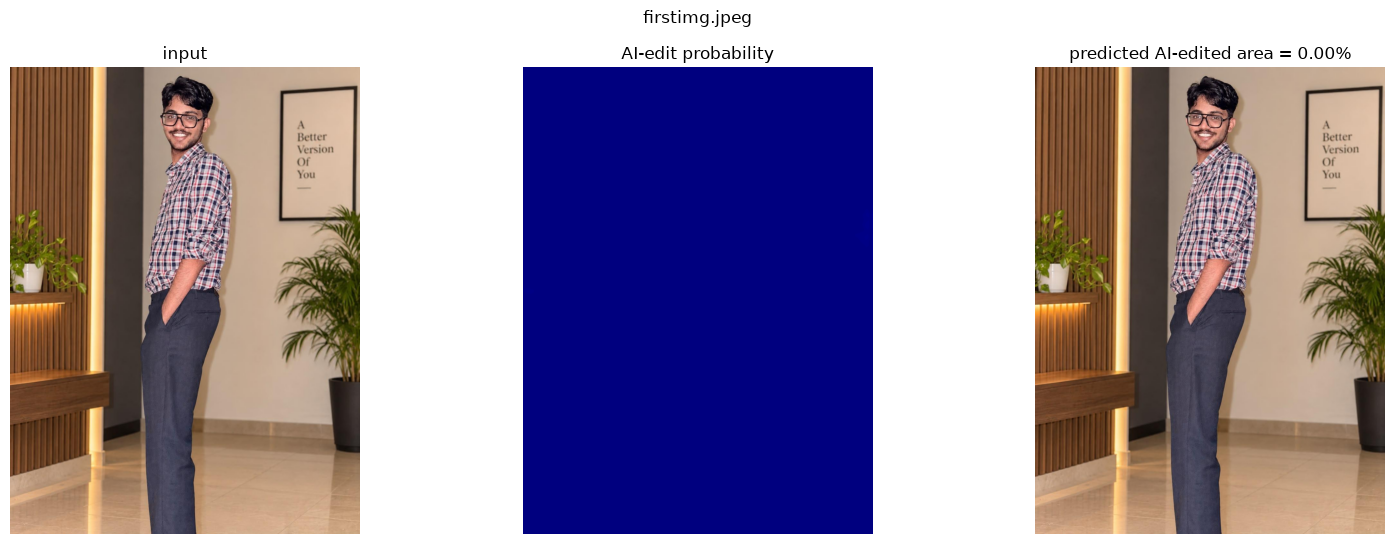

firstimg.jpeg: predicted AI-edited area = 0.00%  (max pixel probability 0.02)


In [5]:
# Put your own image paths here (jpg / png)
result = analyze(r"C:\Users\gopic\Downloads\firstimg.jpeg")

# Several at once:
# for f in Path(r"C:\Users\gopic\Downloads\test_images").glob("*.*"):
#     analyze(f)